# Results

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

In [2]:
# define number of group splits
cv = GroupKFold(n_splits=5)
parameter_type = "tuned"  # "default"

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


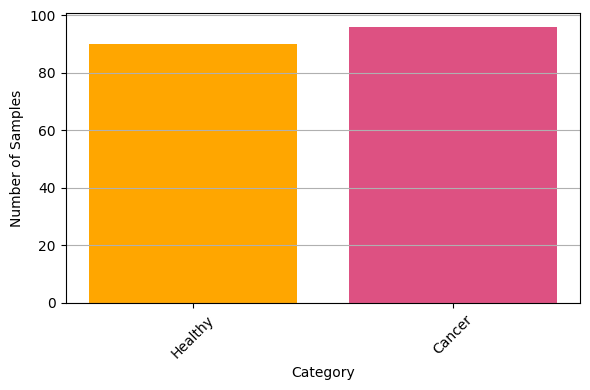


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [3]:
class_task = "healthy_vs_cancer"

n_folds = 5  # number of iterations inside each LPOCV
output_prints = False

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

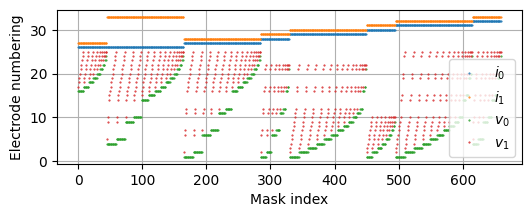

(186, 3300)


In [7]:
Msel = "Adj. far"
Fsel = "Top 5"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="linear", C=0.001, probability=True)

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [9]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [10]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

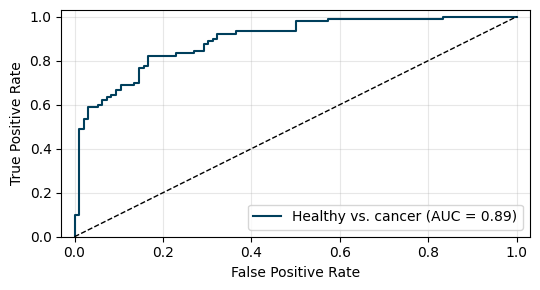

In [11]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

**RF**

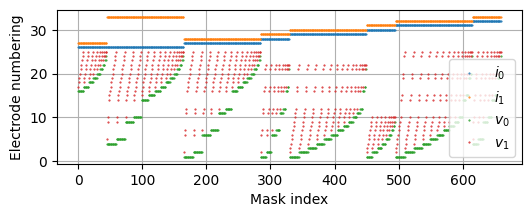

(186, 5280)


In [12]:
Msel = "Adj. far"
Fsel = "Top 8"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=2,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [13]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [14]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

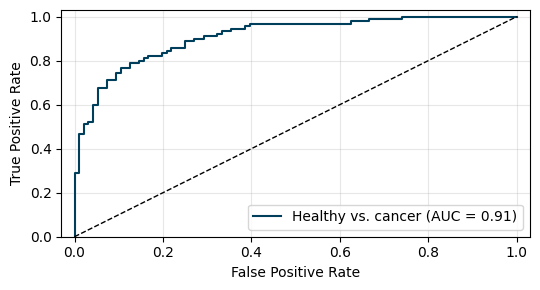

In [15]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_RF.pdf",
)

**LR**

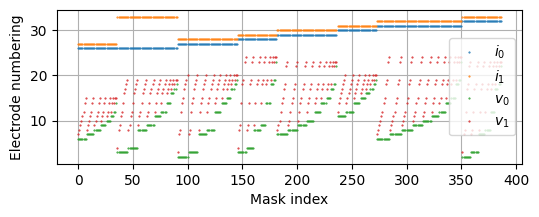

(186, 1935)


In [16]:
Msel = "Med. adj."
Fsel = "Top 5"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [17]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [18]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

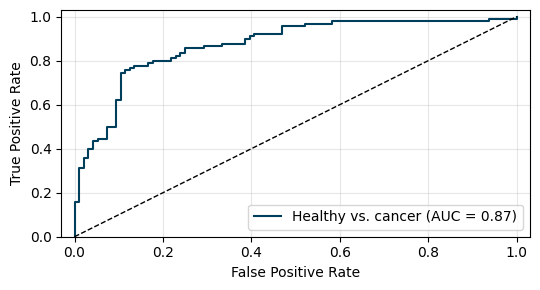

In [19]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_LR.pdf",
)

## Task 2 : Cancer versus HBD


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. HDB

Non-cancer: 162 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Non-cancer']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Non-cancer'): [0, 1]}


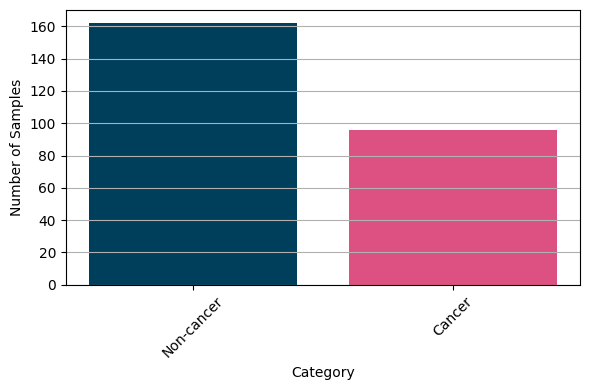


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Non-cancer'}
(258, 31, 7728) (258, 2) (258,)


In [20]:
class_task = "cancer_vs_hbd"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

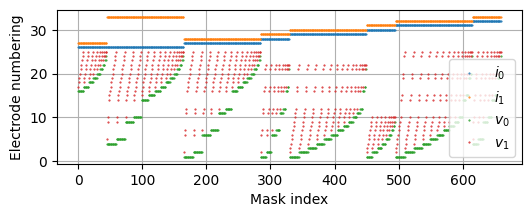

(258, 3300)


In [21]:
Msel = "Adj. far"
Fsel = "Top 5"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="linear", C=0.001, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [22]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [23]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

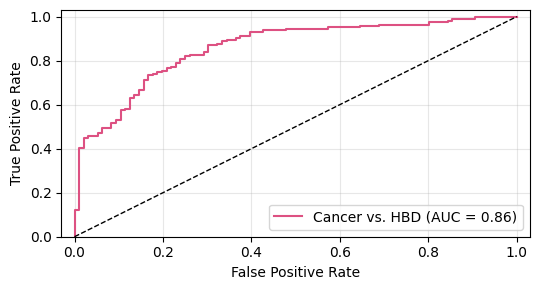

In [24]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

**RF**

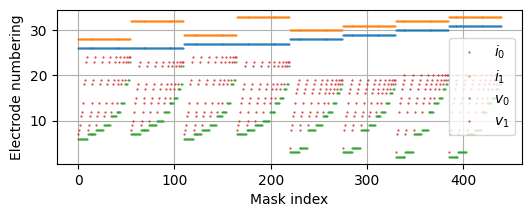

(258, 1320)


In [25]:
Msel = "Skip1 medium"
Fsel = "Top 3"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=800,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=4,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [26]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [27]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

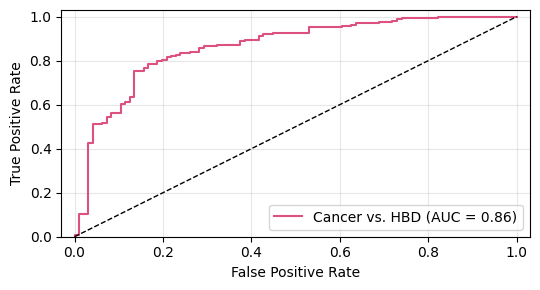

In [28]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_RF.pdf",
)

**LR**

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
type(dd) <class 'list'>
[3, 4, 5, 8, 9, 10, 13, 14, 15]
type(dd) <class 'list'>
[4, 5, 9, 10, 14, 15, 19, 20, 24, 25]
type(dd) <class 'list'>
[13, 14, 15, 18, 19, 20, 23, 24, 25]
type(dd) <class 'list'>
[16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
type(dd) <class 'list'>
[11, 12, 13, 16, 17, 18, 21, 22, 23]
type(dd) <class 'list'>
[1, 2, 6, 7, 11, 12, 16, 17, 21, 22]
type(dd) <class 'list'>
[1, 2, 3, 6, 7, 8, 11, 12, 13]
type(dd) <class 'list'>


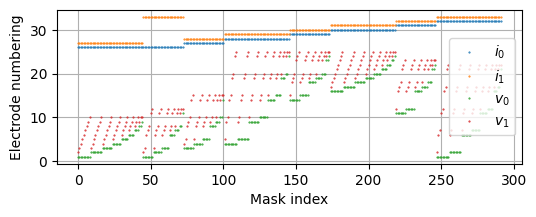

(258, 876)


In [29]:
Msel = "Adj. close"
Fsel = "Top 3"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [30]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [31]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

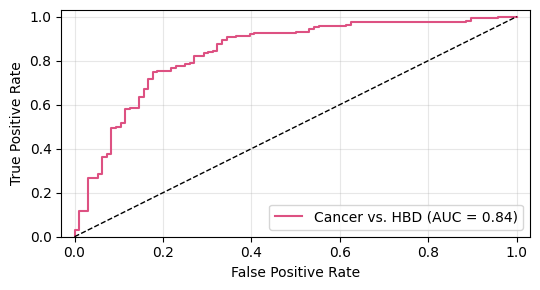

In [32]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_LR.pdf",
)

## Task 3: Multiclass

In [33]:
class_task = "MC"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False  # augmentation done after train test split
)


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
High-grade dysplasia: 29 entries
Non-malignant: 41 entries
Available cases: ['Cancer' 'Healthy' 'High-grade dysplasia' 'Non-malignant']
Coding: -> forward
{np.str_('Cancer'): [1, 0, 0, 0], np.str_('Healthy'): [0, 1, 0, 0], np.str_('High-grade dysplasia'): [0, 0, 1, 0], np.str_('Non-malignant'): [0, 0, 0, 1]}

Inverse mapping: {(1, 0, 0, 0): 'Cancer', (0, 1, 0, 0): 'Healthy', (0, 0, 1, 0): 'High-grade dysplasia', (0, 0, 0, 1): 'Non-malignant'}
(256, 31, 7728) (256, 4) (256,)


**SVM**

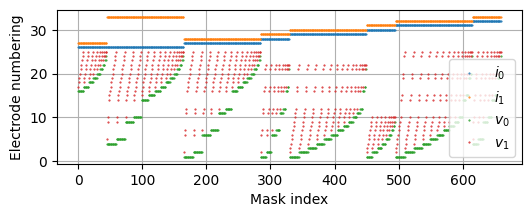

(256, 18480)


In [34]:
Msel = "Adj. far"
Fsel = "Top 28"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="poly", C=0.1, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [35]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [36]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

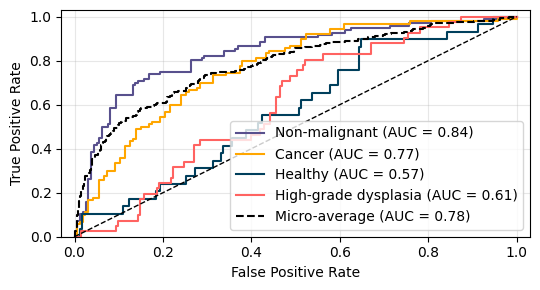

In [37]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

**RF**

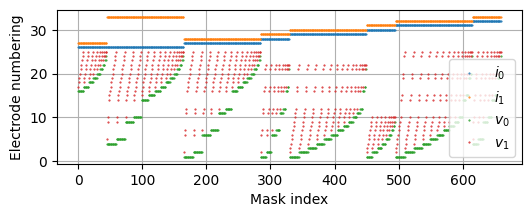

(256, 18480)


In [38]:
Msel = "Adj. far"
Fsel = "Top 28"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="sqrt",
        min_samples_split=2,
        min_samples_leaf=1,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [39]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [40]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

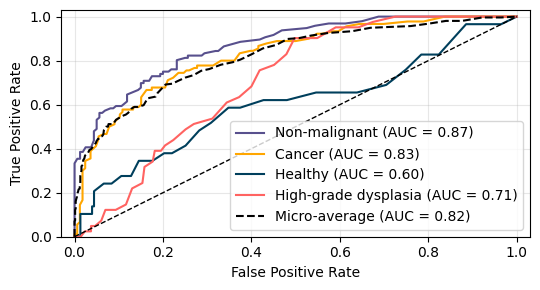

In [41]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_RF.pdf",
)

**LR**

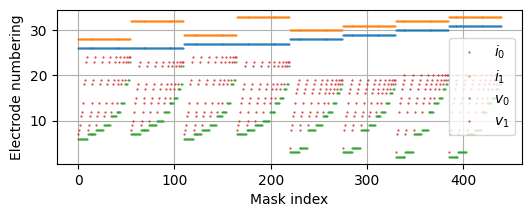

(256, 10120)


In [42]:
Msel = "Skip1 medium"
Fsel = "Top 23"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [43]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [44]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

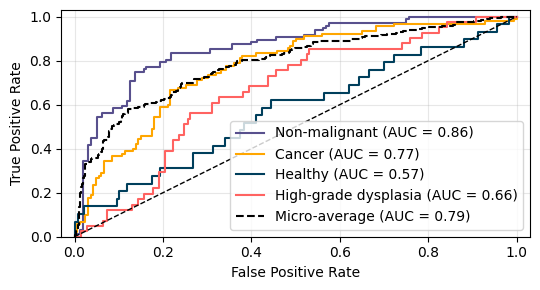

In [46]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_LR.pdf",
)

___